# 01 — Business Framing + EDA (Steps 1 & 2)

## Step 1: Business framing

**Scenario:** A company pays Criteo to show display ads. Two questions:
1. Do the ads actually bring people to the website, or would those people have come anyway? (**incrementality**)
2. Which users should see the ad? (**targeting / uplift**)

| Item | Value |
|---|---|
| Primary metric | `visit` (user came to the website) |
| Secondary metric | `conversion` (user bought something) |
| Assumed ad cost | ₹0.50 per ad shown |
| Assumed visit value | ₹5.00 per visit |

**Break-even logic (used in Step 9):** an ad pays for itself only when
`uplift × ₹5 > ₹0.50`, i.e. the ad must raise a user's visit probability by **more than 10 percentage points**.
If the average uplift is far below that, "show everyone" loses money and we have to target high-uplift users only.
This becomes the core argument of the project.

> The cost and value figures are assumptions, not real prices. Step 9 runs a sensitivity analysis on them.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_criteo, FEATURES, AD_COST, VISIT_VALUE

FIG = Path.cwd().parent / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Break-even uplift needed:", AD_COST / VISIT_VALUE)

Break-even uplift needed: 0.1


## Step 2: EDA

### 2.1 Load data (10% random sample, float32)

In [2]:
df = load_criteo(percent10=True)
print("Shape:", df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print("Nulls:", int(df.isna().sum().sum()))
df.head()

Shape: (1397959, 16)
Memory: 72.7 MB
Nulls: 0


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,21.2655,10.0597,8.2144,4.6799,10.2805,4.1155,-12.6418,4.8338,3.9719,13.1901,5.3004,-0.1687,0,0,0,0
1,25.7443,10.0597,8.2144,4.6799,10.2805,4.1155,-3.2821,4.8338,3.9719,13.1901,5.3004,-0.1687,1,0,0,0
2,12.6164,10.0597,8.8135,4.6799,10.2805,4.1155,0.2944,4.8338,3.9065,13.1901,5.3004,-0.1687,1,0,0,0
3,12.6164,10.0597,8.8763,4.6799,10.2805,4.1155,0.2944,4.8338,3.8959,13.1901,5.3004,-0.1687,1,0,0,0
4,12.6164,10.0597,9.0071,4.6799,10.2805,4.1155,0.2944,4.8338,3.8901,13.1901,5.3004,-0.1687,1,0,0,0


### 2.2 Treatment / control split
Expected ~85:15, **not 50:50**. Every test in this project has to use this ratio.

In [3]:
split = df["treatment"].value_counts().sort_index().rename({0: "control", 1: "treatment"})
split_df = pd.DataFrame({"users": split, "share": split / split.sum()})
split_df

,users,share
treatment,,
control,209220,0.1497
treatment,1188739,0.8503


### 2.3 Visit & conversion rate: treatment vs control

In [4]:
rates = (df.groupby("treatment")
           .agg(users=("visit", "size"),
                visit_rate=("visit", "mean"),
                conversion_rate=("conversion", "mean"),
                exposure_rate=("exposure", "mean"))
           .rename(index={0: "control", 1: "treatment"}))
rates

,users,visit_rate,conversion_rate,exposure_rate
treatment,,,,
control,209220,0.0382,0.0020,0.0000
treatment,1188739,0.0489,0.0032,0.0360


In [5]:
for m in ["visit", "conversion"]:
    t = df.loc[df.treatment == 1, m].mean()
    c = df.loc[df.treatment == 0, m].mean()
    print(f"{m:11s} treat={t:.4%}  control={c:.4%}  abs lift={t-c:+.4%} "
          f"({(t-c)*1e4:+.1f} per 10k users)  rel lift={(t/c-1):+.1%}")

avg_uplift = df.loc[df.treatment == 1, "visit"].mean() - df.loc[df.treatment == 0, "visit"].mean()
print(f"\nAverage visit uplift = {avg_uplift:.4f} vs break-even {AD_COST/VISIT_VALUE:.2f}")
print(f"Avg value per ad = ₹{avg_uplift*VISIT_VALUE:.4f} vs cost ₹{AD_COST:.2f}")

visit       treat=4.8850%  control=3.8185%  abs lift=+1.0665% (+106.7 per 10k users)  rel lift=+27.9%
conversion  treat=0.3196%  control=0.1964%  abs lift=+0.1231% (+12.3 per 10k users)  rel lift=+62.7%

Average visit uplift = 0.0107 vs break-even 0.10
Avg value per ad = ₹0.0533 vs cost ₹0.50


### 2.4 Exposure: treatment ≠ exposure
Treatment = the user was *assigned* to see ads. Exposure = the user *actually saw* an ad.
Exposure should be 0 in control (one-sided non-compliance).

In [6]:
pd.crosstab(df["treatment"], df["exposure"], margins=True)

exposure,0,1,All
treatment,,,
0,209220,0,209220
1,1145936,42803,1188739
All,1355156,42803,1397959


In [7]:
# Preview only: exposed vs unexposed inside the TREATMENT group. This comparison is BIASED - see Step 4.
tg = df[df.treatment == 1]
naive = tg.groupby("exposure")[["visit", "conversion"]].mean().rename(index={0: "not exposed", 1: "exposed"})
naive.loc["control (all)"] = df.loc[df.treatment == 0, ["visit", "conversion"]].mean()
naive

,visit,conversion
exposure,,
not exposed,0.0350,0.0012
exposed,0.4183,0.0559
control (all),0.0382,0.0020


### 2.5 Funnel: visit → conversion

In [8]:
funnel = df.groupby("treatment").apply(
    lambda g: pd.Series({"visit_rate": g.visit.mean(),
                         "conv_given_visit": g.loc[g.visit == 1, "conversion"].mean(),
                         "conv_without_visit": g.loc[g.visit == 0, "conversion"].sum()}),
    include_groups=False).rename(index={0: "control", 1: "treatment"})
funnel

,visit_rate,conv_given_visit,conv_without_visit
treatment,,,
control,0.0382,0.0514,0.0000
treatment,0.0489,0.0654,0.0000


### 2.6 Feature distributions

In [9]:
desc = df[FEATURES].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["n_unique"] = df[FEATURES].nunique()
desc["mode_share"] = [df[f].value_counts(normalize=True).iloc[0] for f in FEATURES]
desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,n_unique,mode_share
f0,"1,397,959.0000",19.6251,5.3786,12.6164,12.6164,12.6164,21.9280,24.4544,26.6734,26.7453,772400,0.2650
f1,"1,397,959.0000",10.0700,0.1049,10.0597,10.0597,10.0597,10.0597,10.0597,10.6795,15.0696,35,0.9877
f2,"1,397,959.0000",8.4466,0.2993,8.2144,8.2144,8.2144,8.2144,8.7238,9.0430,9.0520,421553,0.5226
f3,"1,397,959.0000",4.1800,1.3348,-7.6052,-1.7001,4.6799,4.6799,4.6799,4.6799,4.6799,391,0.8191
f4,"1,397,959.0000",10.3391,0.3431,10.2805,10.2805,10.2805,10.2805,10.2805,11.9733,20.2573,140,0.9564
f5,"1,397,959.0000",4.0282,0.4321,-6.9006,2.2309,4.1155,4.1155,4.1155,4.1155,4.1155,69,0.9469
f6,"1,397,959.0000",-4.1555,4.5754,-29.3062,-17.7582,-6.6993,-2.4111,0.2944,0.2944,0.2944,1094,0.2650
f7,"1,397,959.0000",5.1022,1.2060,4.8338,4.8338,4.8338,4.8338,4.8338,11.4788,11.9982,72882,0.9469
f8,"1,397,959.0000",3.9336,0.0567,3.6351,3.7516,3.9108,3.9719,3.9719,3.9719,3.9719,2297,0.5226
f9,"1,397,959.0000",16.0219,7.0146,13.1901,13.1901,13.1901,13.1901,13.1901,44.8936,72.6572,958,0.7954


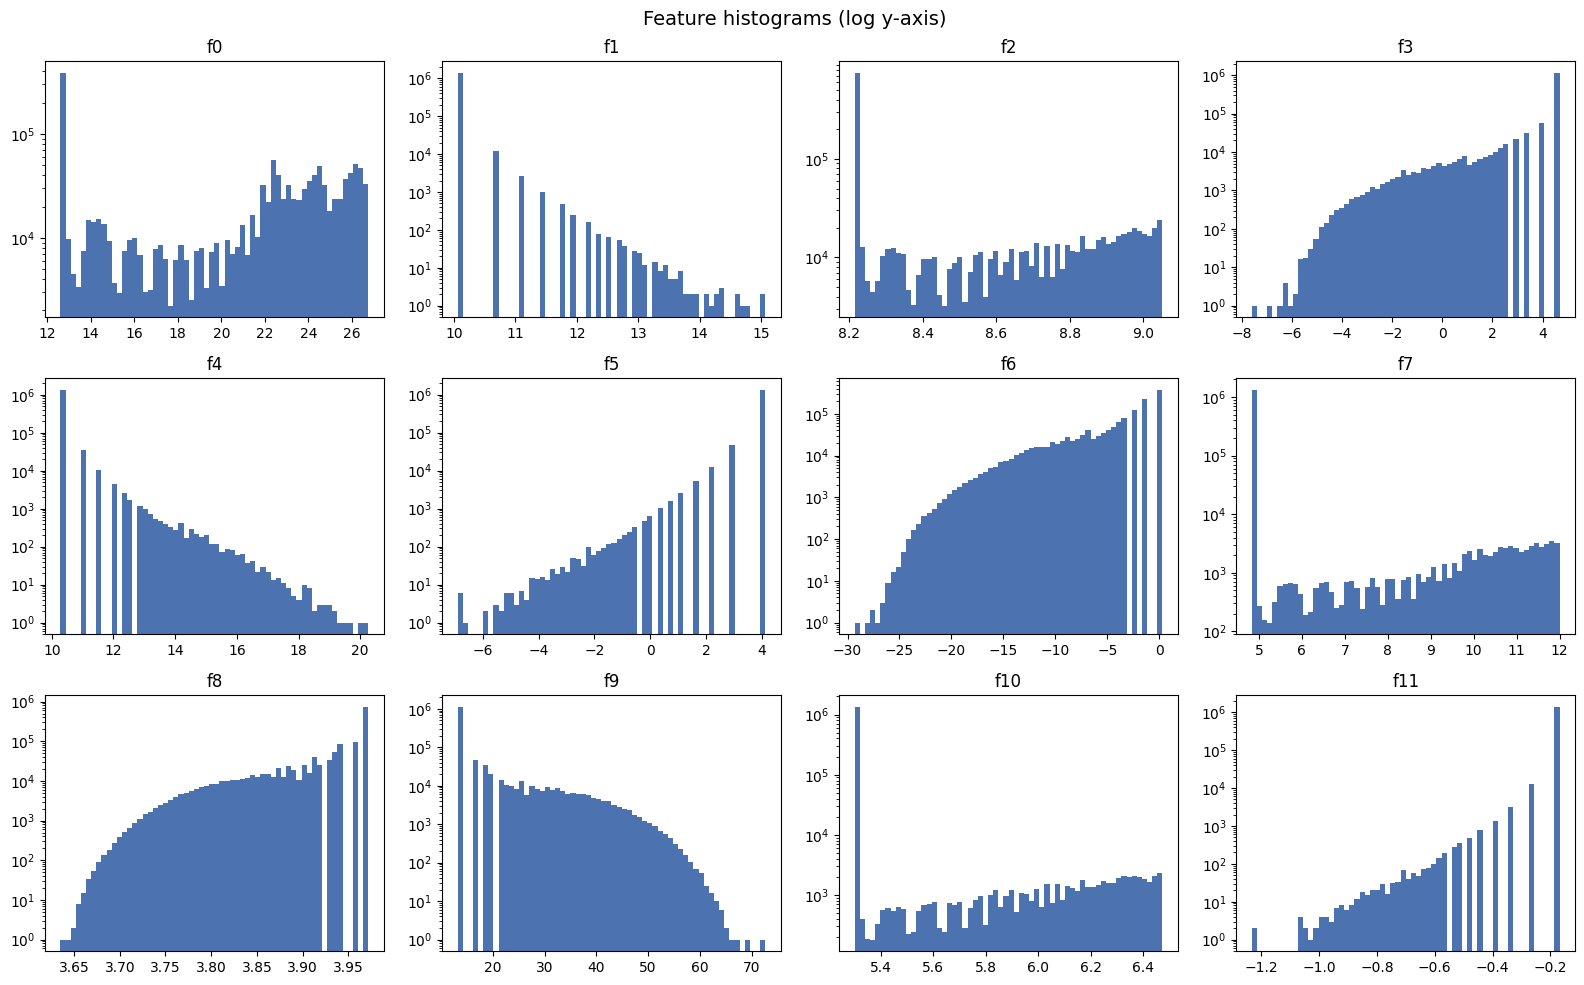

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.hist(df[f], bins=60, color="#4C72B0")
    ax.set_yscale("log")
    ax.set_title(f)
fig.suptitle("Feature histograms (log y-axis)", fontsize=14)
fig.tight_layout()
fig.savefig(FIG / "01_feature_histograms.png", dpi=110)
plt.show()

### 2.7 Outliers
Share of outliers by the IQR rule. The features are anonymized and scaled, so we **do not drop outliers**:
tree models (LightGBM) handle them well, and dropping rows could break the randomization balance.

In [11]:
q1, q3 = df[FEATURES].quantile(.25), df[FEATURES].quantile(.75)
iqr = q3 - q1
outlier_share = ((df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)).mean()
outlier_share.sort_values(ascending=False).to_frame("outlier_share")

,outlier_share
f9,0.2046
f3,0.1809
f8,0.0659
f5,0.0531
f7,0.0531
f10,0.0436
f4,0.0436
f11,0.0147
f6,0.0127
f1,0.0123


### 2.8 Correlations

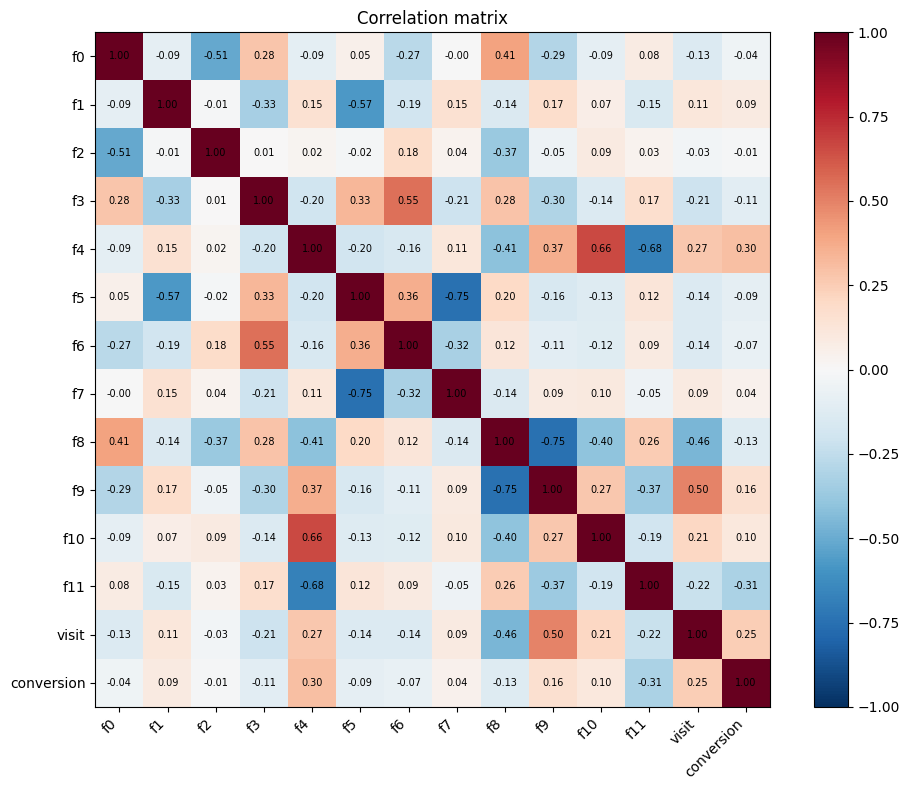

In [12]:
corr = df[FEATURES + ["visit", "conversion"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Correlation matrix")
fig.tight_layout()
fig.savefig(FIG / "01_correlation.png", dpi=110)
plt.show()

In [13]:
corr[["visit", "conversion"]].drop(["visit", "conversion"]).sort_values("visit", key=abs, ascending=False)

,visit,conversion
f9,0.4983,0.1584
f8,-0.4598,-0.1322
f4,0.2707,0.3023
f11,-0.2195,-0.3140
f10,0.2093,0.1022
f3,-0.2082,-0.1076
f5,-0.1392,-0.0911
f6,-0.1381,-0.0739
f0,-0.1349,-0.0392
f1,0.1119,0.0891


### 2.9 Summary
_(The cell below prints the key numbers; the takeaways are at the end of the notebook.)_

In [14]:
print(f"Rows: {len(df):,}")
print(f"Treatment share: {df.treatment.mean():.2%}")
print(f"Visit rate      T={rates.loc['treatment','visit_rate']:.3%}  C={rates.loc['control','visit_rate']:.3%}")
print(f"Conversion rate T={rates.loc['treatment','conversion_rate']:.3%}  C={rates.loc['control','conversion_rate']:.3%}")
print(f"Exposure rate in treatment: {rates.loc['treatment','exposure_rate']:.2%}")
print(f"Exposure rate in control:   {rates.loc['control','exposure_rate']:.2%}")

Rows: 1,397,959
Treatment share: 85.03%
Visit rate      T=4.885%  C=3.818%
Conversion rate T=0.320%  C=0.196%
Exposure rate in treatment: 3.60%
Exposure rate in control:   0.00%


## Key takeaways (Steps 1-2)

1. **Split is ~85:15** (85.03% treatment): every test uses this ratio, not 50:50.
2. **Visit:** treatment 4.89% vs control 3.82% → +1.07 pp absolute (+28% relative), i.e. ~107 extra visits per 10,000 users.
3. **Conversion:** treatment 0.32% vs control 0.20% → +0.12 pp (+63% relative). The base rate is tiny, so power will be low (Step 5).
4. **Only 3.6% of treatment users were exposed**; 0% in control (one-sided non-compliance, so the CACE estimate will be clean).
5. **Evidence of selection bias:** unexposed treatment users visit at 3.50%, even lower than control (3.82%).
   Exposure is not random: the people who saw the ad were already more active. The naive exposed-vs-unexposed gap (~38 pp)
   is therefore wrong. Rough CACE = 1.07 pp / 3.6% ≈ 30 pp (Step 4 adds a confidence interval).
6. **Conversions happen only after a visit** (no conversion without a visit), so the funnel is visit → conversion.
7. **Features:** most features sit on one default value (mode share 80–99%). Some pairs have exactly the same mode share
   (f0/f6, f2/f8, f4/f10, f5/f7), probably the same missing-value pattern. This is why the IQR rule flags so many "outliers",
   so we keep them. Strongest correlations with visit: f9 (+0.50), f8 (−0.46), f4 (+0.27).
8. **Business warning (for ROI):** if ₹0.50 is paid for every *assigned* user, an average uplift of 1.07 pp is worth
   only ~₹0.05 against a ₹0.50 cost, so targeting everyone loses money. If the cost is paid only per *exposed* user (impression),
   the per-exposed effect is ~30 pp, which is above the 10 pp break-even. **Step 9 must define the cost model clearly.**